# Notebook 06 — Snapshot Redesign: Prediksi Repeat Purchase
**Project:** Churn Prediction · Olist Brazilian E-Commerce
**Input:** `data/processed/master.csv` + `data/raw/olist_order_reviews_dataset.csv`
**Output:** `outputs/figures/snapshot_*.png` (model & metrics dihasilkan `train_snapshot_pipeline.py`)

> **Konteks:** Uji placebo di NB04 menunjukkan model churn lama sebagian besar mengenali *kapan* customer berbelanja, bukan *apakah* mereka akan kembali. Penyebabnya ada di definisi label: `is_churned` identik dengan "order terakhir sebelum 19 Juli 2018", sementara fitur diambil dari seluruh histori — termasuk periode yang sama dengan label.
>
> Notebook ini membangun ulang masalahnya dengan **desain snapshot**, standar industri untuk prediksi churn / repeat purchase.

---

## Tujuan
Memprediksi **customer mana yang akan melakukan order lagi dalam 90 hari ke depan**, dengan desain yang tidak memungkinkan informasi masa depan bocor ke fitur.

## Alur Kerja
1. Pilih tanggal snapshot berdasarkan kelengkapan data
2. Bangun snapshot: fitur dari masa lalu, label dari masa depan
3. EDA singkat: siapa yang kembali?
4. Training XGBoost + baseline, evaluasi **out-of-time**
5. Uji signifikansi (bootstrap) — apakah model lebih baik dari aturan sederhana?
6. Interpretasi model
7. Implikasi bisnis

## Keputusan Desain Utama

| Keputusan | Pilihan | Alasan |
|---|---|---|
| Target | `is_repeat` = order baru di [T, T + 90 hari) | Pertanyaan bisnis yang sebenarnya: siapa yang akan kembali? |
| Fitur | Hanya dari order dengan timestamp < T | Tidak ada informasi masa depan di fitur |
| Review | Hanya review dengan `review_creation_date` < T | Median jeda order → review 10 hari; tanpa filter, review masa depan ikut bocor |
| Populasi | Customer dengan ≥ 1 order sebelum T | Hanya customer yang sudah dikenal yang bisa di-scoring |
| Validasi | Out-of-time: train di snapshot lama, test di snapshot terbaru | Meniru kondisi produksi — model selalu dipakai untuk periode setelah training |
| Metric utama | PR-AUC, precision@top-k, lift | Positive rate < 1% — ROC-AUC saja kurang informatif |

> Logika snapshot dan training ada di `src/features/snapshot.py` dan `src/models/snapshot_model.py` (dicakup unit test di `tests/test_snapshot.py`). Notebook ini meng-import fungsi yang sama agar hasilnya identik dengan `train_snapshot_pipeline.py`.

In [1]:
# Import & Setup
import sys
sys.path.insert(0, '..')

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.metrics import precision_recall_curve

from src.features.snapshot import build_snapshot, build_snapshots, load_reviews, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET
from src.models.snapshot_model import train_and_evaluate, ranking_metrics

sns.set_theme(style="darkgrid")

master  = pd.read_csv("../data/processed/master.csv", parse_dates=['order_purchase_timestamp'])
reviews = load_reviews("../data/raw")

print(f"Master  : {master.shape}")
print(f"Reviews : {reviews.shape}")
print(f"Rentang order: {master['order_purchase_timestamp'].min().date()} s/d {master['order_purchase_timestamp'].max().date()}")

Master  : (113425, 23)
Reviews : (99224, 3)
Rentang order: 2016-09-04 s/d 2018-10-17


## Memilih Tanggal Snapshot

Jendela label (T sampai T + 90 hari) harus **sepenuhnya** berada di periode yang datanya lengkap. Jika jendela label menyentuh bulan yang datanya terpotong, customer akan terlihat "tidak kembali" padahal datanya saja yang tidak ada — masalah *right-censoring* yang sama seperti di desain lama.

Cell di bawah memeriksa jumlah order per bulan dan repeat rate 90 hari untuk beberapa kandidat tanggal snapshot.

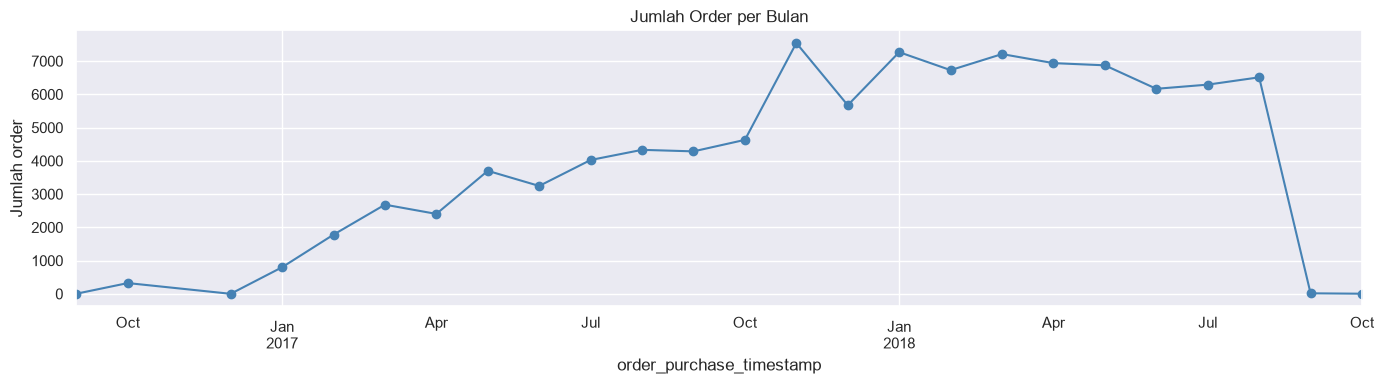

Order per bulan (2018):
order_purchase_timestamp
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M



    cutoff akhir jendela label  customers  repeaters  repeat rate
2017-03-01          2017-05-30       2842         17       0.0060
2017-06-01          2017-08-30      11426        101       0.0088
2017-09-01          2017-11-30      22643        205       0.0091
2017-12-01          2018-03-01      38547        312       0.0081
2018-03-01          2018-05-30      57510        403       0.0070
2018-06-01          2018-08-30      77808        440       0.0057


In [2]:
# Kelengkapan data per bulan
orders = master.drop_duplicates('order_id')
monthly = orders.groupby(orders['order_purchase_timestamp'].dt.to_period('M')).size()

plt.figure(figsize=(14, 4))
monthly.plot(marker='o', color='steelblue')
plt.title('Jumlah Order per Bulan')
plt.ylabel('Jumlah order')
plt.tight_layout()
plt.show()

print("Order per bulan (2018):")
print(monthly.loc['2018-01':].to_string())

# Repeat rate 90 hari per kandidat snapshot
cand_rows = []
for T in ['2017-03-01', '2017-06-01', '2017-09-01', '2017-12-01', '2018-03-01', '2018-06-01']:
    snap = build_snapshot(master, T)
    cand_rows.append({
        'cutoff': T,
        'akhir jendela label': (pd.Timestamp(T) + pd.Timedelta(days=90)).date(),
        'customers': len(snap),
        'repeaters': int(snap[TARGET].sum()),
        'repeat rate': round(snap[TARGET].mean(), 4),
    })
print()
print(pd.DataFrame(cand_rows).to_string(index=False))

## Hasil Pemilihan Tanggal Snapshot

- **Data order praktis berhenti di akhir Agustus 2018.** September dan Oktober 2018 hanya berisi 16 dan 4 order, padahal bulan-bulan sebelumnya 6,000–7,000 order
- Konsekuensi untuk desain lama: "90 hari terakhir" sebelum 17 Okt 2018 sebenarnya hanya berisi **~43 hari data** (19 Jul – 31 Agu). Sebagian customer yang terlabel churn mungkin saja kembali di Sep–Okt, tetapi datanya tidak ada
- **Snapshot terakhir yang valid adalah 1 Juni 2018** — jendela labelnya berakhir 30 Agu 2018, masih di dalam periode data lengkap
- **Repeat rate 90 hari sangat kecil: 0.57%–0.91%.** Ini gambaran yang lebih jujur dibanding "churn rate 89.9%" — hampir semua customer Olist memang tidak kembali dalam 3 bulan
- Snapshot Mar 2017 hanya punya 17 repeater — terlalu sedikit, sehingga tidak dipakai

## Desain Snapshot

```
            fitur (masa lalu)          label (90 hari ke depan)
Train   ────────────────────────┤ 2017-06-01 ├──────────────┤
Train   ──────────────────────────────┤ 2017-09-01 ├──────────────┤
Train   ────────────────────────────────────┤ 2017-12-01 ├──────────────┤
Val     ──────────────────────────────────────────┤ 2018-03-01 ├──────────────┤
Test    ────────────────────────────────────────────────┤ 2018-06-01 ├──────────────┤ 2018-08-30
```

- **Train:** tiga snapshot 2017 (Jun, Sep, Des). Satu customer bisa muncul di beberapa snapshot dengan fitur berbeda — wajar, karena kondisinya memang berbeda di setiap titik waktu
- **Validation:** snapshot Mar 2018 — dipakai untuk memilih hyperparameter
- **Test:** snapshot Jun 2018 — tidak disentuh sampai evaluasi akhir. Jendela labelnya (s/d 30 Agu 2018) adalah jendela terakhir yang datanya masih lengkap
- Jendela label semua snapshot train berakhir sebelum snapshot validation dimulai, dan jendela label validation berakhir sebelum snapshot test — tidak ada tumpang tindih label antar bagian

In [3]:
# Bangun Snapshot
TRAIN_CUTOFFS = ['2017-06-01', '2017-09-01', '2017-12-01']
VAL_CUTOFF    = '2018-03-01'
TEST_CUTOFF   = '2018-06-01'

train_df = build_snapshots(master, TRAIN_CUTOFFS, reviews=reviews)
val_df   = build_snapshots(master, [VAL_CUTOFF],  reviews=reviews)
test_df  = build_snapshots(master, [TEST_CUTOFF], reviews=reviews)

summary = pd.concat([
    train_df.assign(bagian='train'), val_df.assign(bagian='validation'), test_df.assign(bagian='test')
]).groupby(['bagian', 'snapshot_date'], sort=False).agg(
    customers=(TARGET, 'size'),
    repeaters=(TARGET, 'sum'),
    repeat_rate=(TARGET, 'mean'),
)
print(summary.round(4).to_string())
print(f"\nTotal baris train: {len(train_df):,} | positif: {train_df[TARGET].sum():,}")
print(f"Fitur numerik    : {len(NUMERIC_FEATURES)} | fitur kategorikal: {len(CATEGORICAL_FEATURES)}")
print(f"Missing per fitur (train):")
print(train_df[NUMERIC_FEATURES].isnull().mean().loc[lambda s: s > 0].round(4).to_string())

                          customers  repeaters  repeat_rate
bagian     snapshot_date                                   
train      2017-06-01         11426        101       0.0088
           2017-09-01         22643        205       0.0091
           2017-12-01         38547        312       0.0081
validation 2018-03-01         57510        403       0.0070
test       2018-06-01         77808        440       0.0057

Total baris train: 72,616 | positif: 618
Fitur numerik    : 16 | fitur kategorikal: 3
Missing per fitur (train):
avg_order_value     0.0000
avg_installments    0.0000
max_installments    0.0000
avg_price           0.0124
avg_freight         0.0124
freight_ratio       0.0124
avg_review_score    0.1103
min_review_score    0.1103


## Hasil Pembentukan Snapshot

| Bagian | Snapshot | Customer | Repeater | Repeat rate |
|---|---|---|---|---|
| Train | 2017-06-01 | 11,426 | 101 | 0.88% |
| Train | 2017-09-01 | 22,643 | 205 | 0.91% |
| Train | 2017-12-01 | 38,547 | 312 | 0.81% |
| Validation | 2018-03-01 | 57,510 | 403 | 0.70% |
| Test | 2018-06-01 | 77,808 | 440 | 0.57% |

- Total train: 72,616 baris dengan 618 repeater
- **Missing values:** `avg_review_score` & `min_review_score` 11% (review belum ditulis sebelum T, atau customer tidak memberi review) dan `avg_price`/`avg_freight` 1.2% (order tanpa data item). Semuanya diimputasi median di dalam pipeline
- Repeat rate menurun dari waktu ke waktu (0.9% → 0.57%): populasi bertambah cepat dengan customer baru yang mayoritas one-time buyer. Ini juga alasan validasi harus out-of-time — model harus bekerja di distribusi yang sedikit berbeda dari data training

## EDA Singkat: Siapa yang Kembali?

Sebelum modeling, cek repeat rate per segmen di data **train** (bukan test) untuk melihat sinyal apa yang tersedia.

Base repeat rate (train): 0.0085

                customers  repeat_rate    lift
recency_bucket                                
0-30                15459       0.0124  1.4594
31-90               20359       0.0078  0.9119
91-180              21957       0.0082  0.9579
181-365             14520       0.0061  0.7121
>365                  321       0.0031  0.3660 

                         customers  repeat_rate    lift
buyer_type                                             
one-time buyer               70683        0.008  0.9343
repeat buyer (>1 order)       1933        0.029  3.4041 

         customers  repeat_rate    lift
wilayah                                
Non-SP       44463       0.0083  0.9778
SP           28153       0.0088  1.0351 

                       customers  repeat_rate    lift
dominant_category                                    
sports_leisure              5618       0.0126  1.4850
bed_bath_table              7032       0.0105  1.2365
health_beauty               552

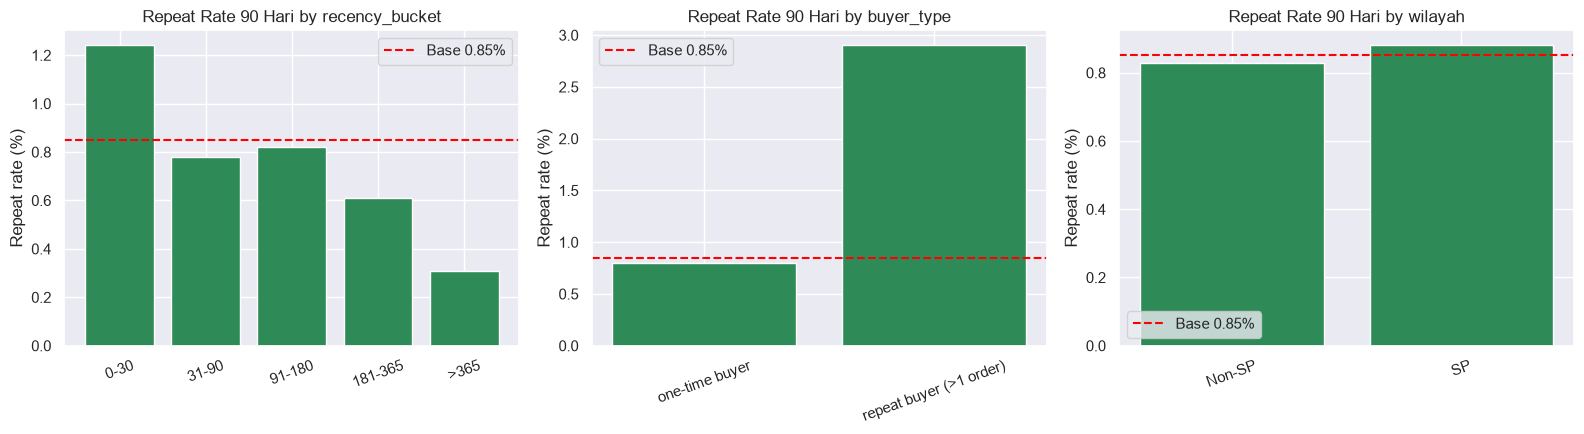

In [4]:
# Repeat rate per segmen (train snapshots)
eda = train_df.copy()
base = eda[TARGET].mean()

eda['recency_bucket'] = pd.cut(eda['recency_days'], [-1, 30, 90, 180, 365, 10_000],
                               labels=['0-30', '31-90', '91-180', '181-365', '>365'])
eda['buyer_type'] = np.where(eda['frequency'] > 1, 'repeat buyer (>1 order)', 'one-time buyer')
eda['wilayah'] = np.where(eda['customer_state'] == 'SP', 'SP', 'Non-SP')

def seg_table(col):
    t = eda.groupby(col, observed=True)[TARGET].agg(['size', 'mean'])
    t.columns = ['customers', 'repeat_rate']
    t['lift'] = t['repeat_rate'] / base
    return t.round(4)

print(f"Base repeat rate (train): {base:.4f}\n")
for col in ['recency_bucket', 'buyer_type', 'wilayah']:
    print(seg_table(col).to_string(), '\n')

top_cat = eda['dominant_category'].value_counts().head(10).index
cat_t = seg_table('dominant_category').loc[top_cat].sort_values('repeat_rate', ascending=False)
print(cat_t.to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['recency_bucket', 'buyer_type', 'wilayah']):
    t = seg_table(col)
    ax.bar(t.index.astype(str), t['repeat_rate'] * 100, color='seagreen', edgecolor='white')
    ax.axhline(base * 100, color='red', linestyle='--', label=f'Base {base:.2%}')
    ax.set_title(f'Repeat Rate 90 Hari by {col}')
    ax.set_ylabel('Repeat rate (%)')
    ax.tick_params(axis='x', rotation=20)
    ax.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/snapshot_segment_repeat_rate.png', dpi=150)
plt.show()

## Hasil EDA Singkat

Base repeat rate 90 hari di data train: **0.85%**.

| Segmen | Repeat rate | Lift |
|---|---|---|
| **Repeat buyer (>1 order sebelumnya)** | 2.90% | **3.40×** |
| One-time buyer | 0.80% | 0.93× |
| Recency 0–30 hari | 1.24% | 1.46× |
| Recency 181–365 hari | 0.61% | 0.71× |
| SP / Non-SP | 0.88% / 0.83% | 1.04× / 0.98× |
| Kategori `sports_leisure` | 1.26% | 1.49× |
| Kategori `bed_bath_table` | 1.05% | 1.24× |
| Kategori `toys` | 0.48% | 0.57× |

- **Pernah kembali sekali adalah sinyal terkuat** — customer yang sudah repeat 3.4× lebih mungkin repeat lagi. Masalah utamanya tetap *activation*: membuat customer melakukan pembelian kedua
- **Recency berpengaruh** — customer yang baru belanja dalam 30 hari terakhir lebih mungkin kembali
- **Wilayah hampir tidak membedakan** (0.88% vs 0.83%) — berbeda dari desain lama yang menunjukkan perbedaan SP vs non-SP lebih besar
- **Kategori habis pakai** (`bed_bath_table`, `health_beauty`) dan `sports_leisure` lebih sering kembali; `toys` paling jarang — konsisten dengan temuan NB04

## Modeling & Baseline

Empat pendekatan dibandingkan di **test snapshot (Jun 2018)**:

| Model | Penjelasan | Peran |
|---|---|---|
| `random` | Skor acak | Batas bawah — precision = base rate |
| `recency_rule` | Urutkan customer dari yang **paling baru** berbelanja | "Model" yang hanya tahu timing — pembanding langsung untuk masalah di desain lama |
| `rfm_logreg` | Logistic Regression di log(recency, frequency, monetary, tenure) | Baseline sederhana & interpretable |
| `xgboost` | Semua fitur (16 numerik + 3 kategorikal), hyperparameter dipilih di validation | Kandidat model utama |

**Kenapa PR-AUC, bukan hanya ROC-AUC?** Positive rate hanya ~0.5–0.9%. Pada data seimbang, ROC-AUC dan PR-AUC sejalan, tetapi pada data yang sangat timpang ROC-AUC bisa terlihat lumayan meski precision-nya sangat rendah. PR-AUC (*average precision*) mengukur kualitas ranking di bagian atas — yang benar-benar dipakai untuk targeting.

**Precision@top-k%:** jika tim marketing hanya menghubungi k% customer dengan skor tertinggi, berapa persen yang benar-benar kembali?

Alur: hyperparameter XGBoost dipilih di validation (grid kecil) → XGBoost & Logistic Regression di-fit ulang di train + validation → semua model dievaluasi sekali di test.

In [5]:
# Training & Evaluasi Out-of-Time
models, snap_metrics, test_scores = train_and_evaluate(train_df, val_df, test_df, n_boot=500)

print("Grid hyperparameter (validation, Mar 2018):")
print(pd.DataFrame(snap_metrics['validation_grid']).to_string(index=False))
print(f"\nTerpilih: {snap_metrics['best_params']}\n")

cols = ['roc_auc', 'pr_auc', 'precision_top1pct', 'precision_top5pct', 'precision_top10pct',
        'recall_top10pct', 'lift_top1pct', 'lift_top10pct']
test_table = pd.DataFrame(snap_metrics['test']).T[cols]
print(f"Test snapshot {snap_metrics['design']['test_snapshot']} — "
      f"{snap_metrics['test']['xgboost']['n']:,} customer, "
      f"{snap_metrics['test']['xgboost']['positives']} repeaters "
      f"(base rate {snap_metrics['test']['xgboost']['base_rate']:.4f})\n")
print(test_table.to_string())

# Cocokkan dengan outputs/metrics_snapshot.json (train_snapshot_pipeline.py)
with open('../outputs/metrics_snapshot.json') as f:
    pipe_snap = json.load(f)
same = all(pipe_snap['test'][m]['pr_auc'] == snap_metrics['test'][m]['pr_auc'] for m in snap_metrics['test'])
print("\n✅ Notebook dan train_snapshot_pipeline.py konsisten" if same else "\n⚠️ Berbeda dengan metrics_snapshot.json")

Grid hyperparameter (validation, Mar 2018):
 max_depth  n_estimators  val_pr_auc  val_roc_auc
         3           200      0.0207       0.5993
         3           400      0.0201       0.5911
         5           200      0.0178       0.5918
         5           400      0.0157       0.5776

Terpilih: {'max_depth': 3, 'n_estimators': 200}

Test snapshot 2018-06-01 — 77,808 customer, 440 repeaters (base rate 0.0056)

              roc_auc  pr_auc  precision_top1pct  precision_top5pct  precision_top10pct  recall_top10pct  lift_top1pct  lift_top10pct
random         0.4833  0.0055             0.0026             0.0054              0.0053           0.0932          0.45           0.93
recency_rule   0.5823  0.0080             0.0077             0.0116              0.0105           0.1864          1.36           1.86
rfm_logreg     0.6017  0.0188             0.0360             0.0159              0.0127           0.2250          6.36           2.25
xgboost        0.6187  0.0192             

## Hasil Training & Evaluasi Out-of-Time

**Pemilihan hyperparameter (validation Mar 2018):** konfigurasi paling sederhana (`max_depth=3`, `n_estimators=200`) memberi PR-AUC validation tertinggi (0.0207). Model yang lebih dalam justru lebih buruk — tanda bahwa dengan hanya 618 positif, model kompleks mudah overfit.

**Hasil di test snapshot Jun 2018 (77,808 customer, 440 repeater, base rate 0.57%):**

| Model | ROC-AUC | PR-AUC | Precision top 1% | Recall top 10% |
|---|---|---|---|---|
| Random | 0.483 | 0.0055 | 0.26% | 9.3% |
| Recency rule | 0.582 | 0.0080 | 0.77% | 18.6% |
| RFM LogReg | 0.602 | 0.0188 | 3.60% | 22.5% |
| **XGBoost** | **0.619** | **0.0192** | **3.86%** | **25.5%** |

- PR-AUC XGBoost **3.5× base rate** (0.0192 vs 0.0055), dan 2.4× recency rule
- ROC-AUC 0.62 terlihat jauh lebih rendah dari model lama (0.82), tetapi kedua angka ini mengukur hal yang berbeda — lihat section **Desain Lama vs Desain Snapshot**
- Hasil notebook identik dengan `outputs/metrics_snapshot.json`

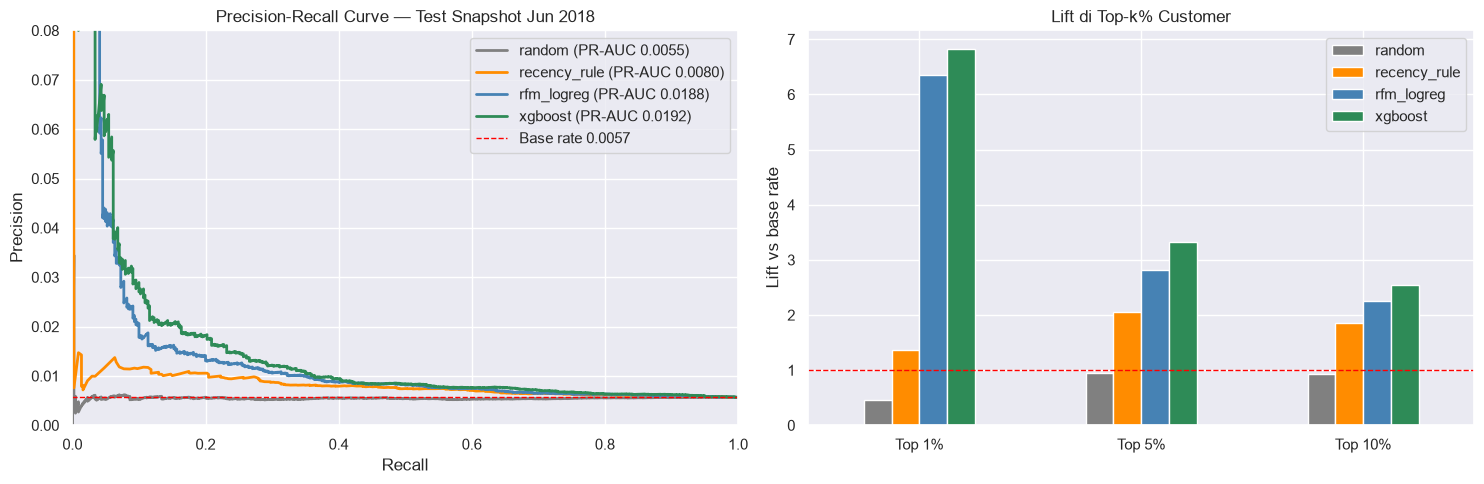

         random  recency_rule  rfm_logreg  xgboost
Top 1%     0.45          1.36        6.36     6.82
Top 5%     0.95          2.05        2.82     3.32
Top 10%    0.93          1.86        2.25     2.55


In [6]:
# Visualisasi: Precision-Recall Curve & Lift
y_test = test_df[TARGET].to_numpy()
base_rate = y_test.mean()
colors = {'random': 'gray', 'recency_rule': 'darkorange', 'rfm_logreg': 'steelblue', 'xgboost': 'seagreen'}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, s in test_scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    axes[0].plot(r, p, color=colors[name], linewidth=2,
                 label=f"{name} (PR-AUC {snap_metrics['test'][name]['pr_auc']:.4f})")
axes[0].axhline(base_rate, color='red', linestyle='--', linewidth=1, label=f'Base rate {base_rate:.4f}')
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 0.08)
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve — Test Snapshot Jun 2018')
axes[0].legend()

lift_df = pd.DataFrame({name: [snap_metrics['test'][name][f'lift_top{k}pct'] for k in (1, 5, 10)]
                        for name in test_scores}, index=['Top 1%', 'Top 5%', 'Top 10%'])
lift_df.plot(kind='bar', ax=axes[1], color=[colors[c] for c in lift_df.columns], edgecolor='white')
axes[1].axhline(1, color='red', linestyle='--', linewidth=1)
axes[1].set_ylabel('Lift vs base rate')
axes[1].set_title('Lift di Top-k% Customer')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig('../outputs/figures/snapshot_pr_lift.png', dpi=150)
plt.show()

print(lift_df.to_string())

## Hasil Precision-Recall & Lift

| Target | Random | Recency rule | RFM LogReg | XGBoost |
|---|---|---|---|---|
| Top 1% | 0.45× | 1.36× | 6.36× | **6.82×** |
| Top 5% | 0.95× | 2.05× | 2.82× | **3.32×** |
| Top 10% | 0.93× | 1.86× | 2.25× | **2.55×** |

- Kurva PR XGBoost dan RFM LogReg berada di atas recency rule terutama di **recall rendah** — model paling berguna untuk memilih sekelompok kecil customer teratas
- Precision di top 1% mencapai ~3.6–3.9%: masih kecil secara absolut, tetapi ~7× lebih tinggi dari base rate 0.57%
- Recency rule hanya sedikit di atas random, artinya "pilih yang paling baru belanja" saja tidak cukup

## Uji Signifikansi — Apakah Model Benar-benar Lebih Baik?

Dengan hanya ~440 repeater di test set, selisih PR-AUC yang kecil bisa saja kebetulan. Karena itu dipakai **paired bootstrap**: test set di-resample 500 kali (dengan pengembalian), lalu selisih PR-AUC dua model dihitung di setiap sampel.

- Jika **interval kepercayaan 95%** selisihnya tidak memuat 0 → perbedaan signifikan
- `p_value_one_sided` = proporsi sampel bootstrap di mana model A **tidak** lebih baik dari model B

In [7]:
# Hasil Paired Bootstrap (PR-AUC)
sig = pd.DataFrame(snap_metrics['significance']).T
sig.index = ['XGBoost − Recency rule', 'XGBoost − RFM LogReg']
print(sig.to_string())

                          diff  ci_low  ci_high  p_value_one_sided  n_boot
XGBoost − Recency rule  0.0112  0.0044   0.0222              0.000   500.0
XGBoost − RFM LogReg    0.0005 -0.0050   0.0046              0.462   500.0


## Hasil Uji Signifikansi

| Perbandingan | Selisih PR-AUC | CI 95% | p (one-sided) |
|---|---|---|---|
| XGBoost − Recency rule | +0.0112 | [0.0044, 0.0222] | 0.000 |
| XGBoost − RFM LogReg | +0.0005 | [−0.0050, 0.0046] | 0.462 |

- **XGBoost signifikan lebih baik dari aturan recency.** CI tidak memuat 0. Artinya model menangkap sinyal **di luar timing** — berbeda dengan desain lama, di mana uji placebo menunjukkan sinyal didominasi waktu
- **XGBoost tidak signifikan lebih baik dari RFM Logistic Regression.** Selisihnya hampir nol dan CI memuat 0. Fitur tambahan (ongkir, kategori, state, review, cicilan) hampir tidak menambah kemampuan ranking di atas 4 fitur RFM

**Keputusan:** untuk produksi, **RFM Logistic Regression** adalah pilihan yang lebih masuk akal — performa setara, jauh lebih mudah dijelaskan, lebih murah dipelihara, dan lebih kecil risikonya terhadap perubahan distribusi fitur. XGBoost tetap disimpan sebagai challenger.

## Interpretasi Model

Dua sudut pandang:
1. **Koefisien Logistic Regression** — arah dan besar pengaruh fitur RFM (setelah log-transform & standardisasi)
2. **SHAP XGBoost** — arah pengaruh semua fitur di test snapshot

Koefisien RFM Logistic Regression (fitur distandardisasi):
log_recency_days   -0.166
log_frequency       0.229
log_monetary       -0.021
log_tenure_days    -0.059

Koefisien positif = nilai lebih tinggi → peluang repeat lebih besar


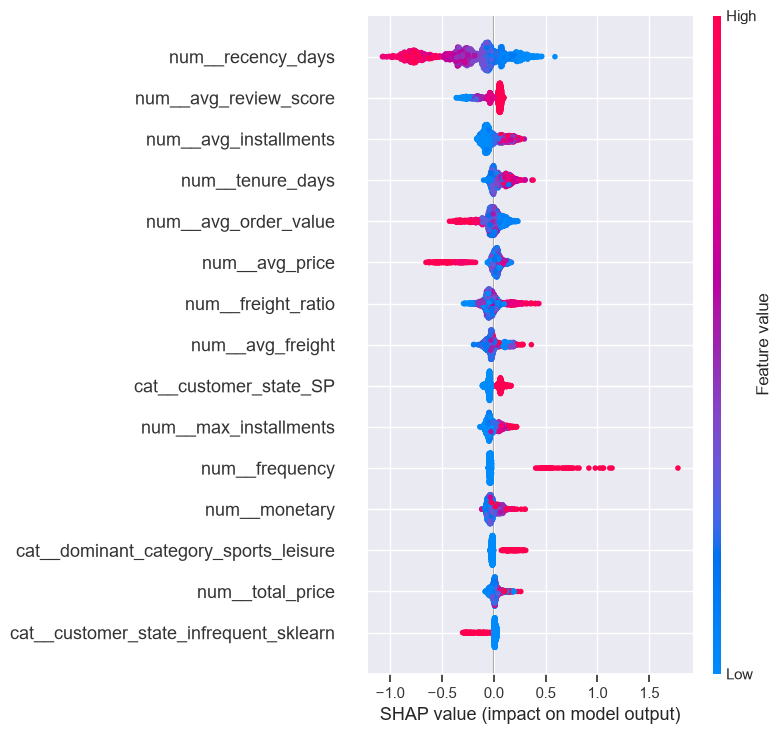

Top 10 fitur (mean |SHAP|), arah > 0 = nilai tinggi menaikkan peluang repeat:
                        mean_abs_shap   arah
num__recency_days               0.314 -0.948
num__avg_review_score           0.088  0.972
num__avg_installments           0.085  0.864
num__tenure_days                0.070  0.738
num__avg_order_value            0.068 -0.653
num__avg_price                  0.066 -0.755
num__freight_ratio              0.065  0.528
num__avg_freight                0.061  0.145
cat__customer_state_SP          0.057  0.941
num__max_installments           0.054  0.852


In [8]:
# Koefisien RFM Logistic Regression
lr = models['rfm_logreg']
coef = pd.Series(lr.named_steps['model'].coef_[0],
                 index=['log_recency_days', 'log_frequency', 'log_monetary', 'log_tenure_days'])
print("Koefisien RFM Logistic Regression (fitur distandardisasi):")
print(coef.round(3).to_string())
print("\nKoefisien positif = nilai lebih tinggi → peluang repeat lebih besar")

# SHAP XGBoost
import shap
xgb = models['xgboost']
X_test = test_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
X_test_tr = pd.DataFrame(xgb.named_steps['pre'].transform(X_test),
                         columns=xgb.named_steps['pre'].get_feature_names_out())
sample = X_test_tr.sample(2000, random_state=42)
explainer = shap.TreeExplainer(xgb.named_steps['model'])
sv = explainer.shap_values(sample)

shap.summary_plot(sv, sample, max_display=15, show=False)
plt.savefig('../outputs/figures/snapshot_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

direction = [np.corrcoef(sample.iloc[:, i], sv[:, i])[0, 1] if sample.iloc[:, i].std() > 0 else np.nan
             for i in range(sv.shape[1])]
shap_tab = pd.DataFrame({'mean_abs_shap': np.abs(sv).mean(axis=0), 'arah': direction},
                        index=sample.columns).sort_values('mean_abs_shap', ascending=False)
print("Top 10 fitur (mean |SHAP|), arah > 0 = nilai tinggi menaikkan peluang repeat:")
print(shap_tab.head(10).round(3).to_string())

## Hasil Interpretasi Model

**RFM Logistic Regression (fitur distandardisasi):**

| Fitur | Koefisien | Artinya |
|---|---|---|
| `log_frequency` | +0.229 | Customer dengan lebih banyak order lebih mungkin kembali — sinyal terkuat |
| `log_recency_days` | −0.166 | Semakin lama sejak order terakhir, semakin kecil peluang kembali |
| `log_tenure_days` | −0.059 | Pengaruh kecil |
| `log_monetary` | −0.021 | Nilai belanja hampir tidak berpengaruh |

**SHAP XGBoost (top fitur):**
- **`recency_days`** — pengaruh terbesar (arah −0.95): customer yang baru belanja lebih mungkin kembali. Di desain snapshot, ini sinyal perilaku yang sah, bukan kebocoran label
- **`avg_review_score`** (+0.97) — customer yang puas lebih mungkin kembali. Di desain lama efek review hampir tidak terlihat
- **`avg_installments`** (+0.86) — customer yang mencicil sedikit lebih mungkin kembali
- **`customer_state_SP`** (+0.94) — customer SP sedikit lebih mungkin kembali, konsisten dengan desain lama
- **`avg_order_value`, `avg_price`** (negatif) — pembeli barang mahal cenderung pembelian sekali
- **`avg_freight`, `freight_ratio`** — pengaruh kecil (mean |SHAP| ~0.06); ongkir bukan penggerak utama

Kedua model sepakat: **frekuensi, recency, dan kepuasan** adalah sinyal utama repeat purchase.

## Desain Lama vs Desain Snapshot

| Aspek | Desain lama (NB02–NB04) | Desain snapshot (NB06) |
|---|---|---|
| Pertanyaan | "Apakah order terakhir > 90 hari sebelum 17 Okt 2018?" | "Apakah customer order lagi dalam 90 hari setelah T?" |
| Fitur | Seluruh histori, termasuk periode label | Hanya data sebelum T |
| Review | Semua review | Hanya review yang sudah ditulis sebelum T |
| `recency` | Harus di-drop (sumber label) | Fitur sah — dihitung relatif terhadap T |
| Positive class | Non-churn 10.1% (sebagian besar "baru belanja") | Repeat purchase 0.57% (test) |
| Validasi | Random split | Out-of-time (train 2017 → test Jun 2018) |
| ROC-AUC | 0.8207 | 0.6187 |
| Uji placebo / baseline timing | Placebo AUC 0.68–0.80 → sinyal didominasi waktu | XGBoost signifikan mengalahkan aturan recency |

**AUC turun dari 0.82 ke 0.62 — dan itu kabar baik.** AUC lama tinggi karena model mengenali periode pembelian. AUC baru lebih rendah, tetapi mengukur hal yang benar: kemampuan meramal pembelian **berikutnya** di periode yang belum pernah dilihat model. Repeat purchase di Olist memang sangat sulit diprediksi — 99.4% customer di test snapshot tidak kembali dalam 90 hari.

## Implikasi Bisnis — Ukuran Targeting

Model tidak dipakai untuk memprediksi satu customer secara pasti, tetapi untuk **mengurutkan** customer sehingga budget kampanye (misalnya voucher second purchase) diarahkan ke kelompok dengan peluang kembali tertinggi.

Cell di bawah menghitung, untuk setiap 10,000 customer yang ditargetkan, berapa customer yang diperkirakan akan kembali **secara alami** (tanpa kampanye) jika target dipilih acak vs dipilih model. Angka ini membantu menentukan berapa besar efek kampanye yang dibutuhkan agar sebanding dengan biayanya — efek kampanye itu sendiri tetap harus diukur dengan A/B test.

In [9]:
# Sizing Targeting per 10,000 Customer
rows = []
for k in (1, 5, 10):
    for name in ['random', 'recency_rule', 'rfm_logreg', 'xgboost']:
        p = snap_metrics['test'][name][f'precision_top{k}pct'] if name != 'random' else base_rate
        rows.append({'target': f'Top {k}%', 'model': name,
                     'precision': round(p, 4), 'repeaters per 10K': round(p * 10_000)})
sizing = pd.DataFrame(rows).pivot(index='target', columns='model', values='repeaters per 10K')
print("Perkiraan customer yang kembali secara alami per 10,000 customer yang ditargetkan:")
sizing = sizing.reindex(['Top 1%', 'Top 5%', 'Top 10%'])
print(sizing[['random', 'recency_rule', 'rfm_logreg', 'xgboost']].to_string())

Perkiraan customer yang kembali secara alami per 10,000 customer yang ditargetkan:
model    random  recency_rule  rfm_logreg  xgboost
target                                            
Top 1%       57            77         360      386
Top 5%       57           116         159      188
Top 10%      57           105         127      144


## Hasil Sizing Targeting

| Target | Random | Recency rule | RFM LogReg | XGBoost |
|---|---|---|---|---|
| Top 1% | 57 | 77 | 360 | 386 |
| Top 5% | 57 | 116 | 159 | 188 |
| Top 10% | 57 | 105 | 127 | 144 |

- Jika kampanye hanya untuk **1% customer teratas** (~780 dari 77,808 customer di test snapshot), model memilih kelompok yang secara alami kembali ~6–7× lebih sering dari pilihan acak
- Semakin besar target, keunggulan model semakin kecil — di top 10%, lift turun ke ~2.5×
- **Implikasi praktis:** model paling berguna untuk kampanye kecil yang terfokus. Untuk program massal (misalnya voucher ke semua customer baru), pemilihan target berbasis model tidak banyak berbeda dari aturan sederhana

> Penting: customer dengan skor tinggi adalah yang **paling mungkin kembali tanpa diberi apa-apa**. Memberi voucher kepada mereka bisa saja hanya "membayar" pembelian yang memang akan terjadi. Kelompok yang paling layak diberi insentif adalah yang **paling terpengaruh** oleh insentif — dan itu hanya bisa diukur dengan A/B test + uplift modeling.

## Summary Notebook 06 — Snapshot Redesign

**Desain:** target `is_repeat` = order baru dalam 90 hari setelah snapshot T. Fitur hanya dari data sebelum T. Train di snapshot Jun/Sep/Des 2017 (72,616 baris, 618 repeater), validation Mar 2018, test out-of-time Jun 2018 (77,808 customer, 440 repeater).

**Hasil di test snapshot Jun 2018:**

| Model | ROC-AUC | PR-AUC | Precision top 1% | Lift top 1% | Lift top 10% |
|---|---|---|---|---|---|
| Random | 0.483 | 0.0055 | 0.26% | 0.45× | 0.93× |
| Recency rule | 0.582 | 0.0080 | 0.77% | 1.36× | 1.86× |
| RFM LogReg | 0.602 | 0.0188 | 3.60% | 6.36× | 2.25× |
| **XGBoost** | **0.619** | **0.0192** | **3.86%** | **6.82×** | **2.55×** |

**Temuan utama:**
- **Sinyalnya nyata tetapi lemah.** Base rate repeat hanya 0.57%; 1% customer dengan skor tertinggi kembali dengan rate ~3.9% (≈ 7× base rate)
- **Model mengalahkan "timing saja" secara signifikan:** PR-AUC XGBoost vs aturan recency +0.011 (CI 95% 0.004–0.022). Berbeda dengan desain lama, sinyalnya bukan sekadar penanda waktu
- **XGBoost tidak signifikan lebih baik dari RFM Logistic Regression** (selisih PR-AUC +0.0005, CI −0.005–0.005). Model 4 fitur yang interpretable sudah menangkap hampir semua sinyal
- **Pembeda terkuat:** riwayat lebih dari satu order (repeat rate 3.4× base), recency yang baru, dan review yang tinggi. Pembeli `toys` paling jarang kembali (0.57×)
- **Ongkir bukan penggerak utama:** `freight_ratio` dan `avg_freight` hanya berpengaruh kecil — konsisten dengan temuan NB02 & NB04

**Rekomendasi model:** gunakan **RFM Logistic Regression** sebagai model produksi pertama — performanya setara XGBoost secara statistik, jauh lebih mudah dijelaskan ke stakeholder, dan lebih stabil. XGBoost disimpan sebagai challenger.

**Keterbatasan:**
- Hanya ~440–618 positif per bagian — CI bootstrap masih lebar
- Hanya satu test snapshot; idealnya dievaluasi di beberapa periode (*backtesting*)
- Model memprediksi siapa yang kembali **secara alami**, bukan siapa yang **terpengaruh** kampanye. Untuk alokasi voucher, langkah berikutnya adalah A/B test lalu *uplift modeling*
- API (`src/api`) masih melayani model churn desain lama; migrasi ke model snapshot membutuhkan skema request baru (`recency_days`, `tenure_days`, dll.)

**Output:** `outputs/metrics_snapshot.json`, `outputs/model_snapshot_xgboost.pkl`, `outputs/model_snapshot_rfm_logreg.pkl` (dari `train_snapshot_pipeline.py`), serta `outputs/figures/snapshot_*.png`.